# 01 - Data Analysis: Bootstrap Pipeline Benchmark

This notebook processes the raw timing log produced by `src/run_experiment.py`, aggregates it and exports the figures used in the README.

**System under test:** bootstrap confidence intervals for OLS coefficients (the core of the Task 2 pipeline), run on synthetic data.
**Methods compared:** `baseline` (one fit per resample in a Python loop) and `proposed` (all resamples solved in one vectorized batch).

Structure of the notebook:

1. Data ingestion and warm-up filtering
2. Statistical aggregation
3. Visualization and export
4. Conclusions

Reusable logic lives in `src/process_data.py` and `src/visualize.py`; the notebook calls these modules instead of duplicating code.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

# Find the repository root whether the notebook is opened from /notebooks or from the root
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import process_data
import visualize

SEED = 42
np.random.seed(SEED)  # fixed seed for sampling and bootstrapping

RAW_PATH = ROOT / "data" / "raw" / "test_run.jsonl"
SUMMARY_PATH = ROOT / "data" / "processed" / "metrics_summary.csv"
FIG_DIR = ROOT / "reports" / "figures"

pd.set_option("display.width", 160)
print("Repository root:", ROOT.name)
print("numpy", np.__version__, "| pandas", pd.__version__)

Repository root: chatbot-repurchase-electronics
numpy 2.1.3 | pandas 2.2.3


## 1. Data ingestion and warm-up filtering

The raw log contains one JSON object per run. For every method and load level the first 5 runs are **warm-up** runs and the next 50 are **evaluation** runs. Warm-up runs capture cold-start effects (memory allocation, cache and thread start-up), so they are discarded before any statistics are computed.

In [2]:
raw = process_data.load_raw(RAW_PATH)
print(f"{len(raw)} runs loaded from {RAW_PATH.name}")
display(raw.head())
display(raw.groupby(["method", "phase"]).size().unstack())

770 runs loaded from test_run.jsonl


,run_id,method,n_respondents,phase,latency_ms,peak_mem_mb,error,seed
0,1,baseline,50,warmup,16.5633,0.0178,False,43
1,2,baseline,50,warmup,7.7819,0.0178,False,44
2,3,baseline,50,warmup,5.7630,0.0178,False,45
3,4,baseline,50,warmup,5.8250,0.0178,False,46
4,5,baseline,50,warmup,5.7880,0.0178,False,47


phase,evaluation,warmup
method,,
baseline,350,35
proposed,350,35


**Cold-start check.** The table below compares the very first run of each (method, load) combination with the median of its evaluation runs. A ratio above 1 shows a cold-start spike; a ratio close to 1 means the effect is small for that case. Warm-up runs are discarded in every case as a standard precaution.

In [3]:
first_run = raw.sort_values("run_id").groupby(["method", "n_respondents"]).first()["latency_ms"]
eval_median = (raw[raw["phase"] == "evaluation"]
               .groupby(["method", "n_respondents"])["latency_ms"].median())
cold = pd.DataFrame({"first_run_ms": first_run, "evaluation_median_ms": eval_median})
cold["first / median"] = cold["first_run_ms"] / cold["evaluation_median_ms"]
display(cold.round(3))

first_run_ms  evaluation_median_ms  first / median
method   n_respondents                                                    
baseline 50                   16.563                 5.981           2.769
         100                   6.294                 6.473           0.972
         200                  11.168                 7.104           1.572
         500                  14.522                 9.873           1.471
         1000                 18.224                14.066           1.296
         2000                 46.835                32.598           1.437
         5000                117.443                74.502           1.576
proposed 50                    8.929                 0.694          12.860
         100                   1.800                 1.420           1.268
         200                   2.930                 2.586           1.133
         500                   7.180                 6.517           1.102
         1000                 13.228                12.225           1.082
         2000                 25.845                23.697           1.091
         5000                 66.773                59.291           1.126

In [4]:
evaluation = raw[(raw["phase"] == "evaluation") & (~raw["error"])]
n_eval_all = int((raw["phase"] == "evaluation").sum())
print(f"Evaluation runs kept: {len(evaluation)} of {n_eval_all}")
print("Failed runs in the evaluation phase:", int(raw[raw["phase"] == "evaluation"]["error"].sum()))

Evaluation runs kept: 700 of 700
Failed runs in the evaluation phase: 0


## 2. Statistical aggregation

For every (method, load) pair the evaluation runs are summarized by the median, mean, standard deviation, quartiles (p25, p75), tail percentiles (p95, p99), a bootstrap 95% confidence interval of the median (2000 resamples, seed 42) and the error rate.

In [5]:
summary = process_data.summarize(raw, np.random.default_rng(SEED))
cols = ["method", "n_respondents", "n_runs", "median_ms", "mean_ms", "sd_ms",
        "p25_ms", "p75_ms", "p95_ms", "p99_ms", "ci_low_ms", "ci_high_ms",
        "error_rate", "peak_mem_mb_median"]
display(summary[cols].round(3))

,method,n_respondents,n_runs,median_ms,mean_ms,sd_ms,p25_ms,p75_ms,p95_ms,p99_ms,ci_low_ms,ci_high_ms,error_rate,peak_mem_mb_median
0,baseline,50,50,5.981,6.468,1.095,5.692,6.911,8.433,9.802,5.730,6.520,0.0,0.018
1,baseline,100,50,6.473,6.919,1.030,6.184,7.282,9.193,9.823,6.327,6.839,0.0,0.021
2,baseline,200,50,7.104,7.608,0.992,6.965,8.074,9.662,10.709,7.020,7.377,0.0,0.028
3,baseline,500,50,9.873,10.382,1.206,9.565,10.970,12.923,13.887,9.599,10.435,0.0,0.049
4,baseline,1000,50,14.066,14.867,1.645,13.903,15.117,18.515,19.938,13.961,14.399,0.0,0.083
5,baseline,2000,50,32.598,36.401,10.132,31.814,38.470,47.272,74.953,32.041,35.843,0.0,0.152
6,baseline,5000,50,74.502,75.835,5.928,72.606,76.163,84.764,100.466,73.754,75.071,0.0,0.358
7,proposed,50,50,0.694,0.867,0.541,0.674,0.896,1.233,2.992,0.675,0.736,0.0,0.194
8,proposed,100,50,1.420,1.468,0.183,1.390,1.513,1.671,2.150,1.402,1.465,0.0,0.306
9,proposed,200,50,2.586,2.660,0.213,2.495,2.786,3.056,3.266,2.544,2.674,0.0,0.611


In [6]:
# Consistency check: the notebook must reproduce the file written by src/process_data.py
saved = pd.read_csv(SUMMARY_PATH)
pd.testing.assert_frame_equal(
    saved[cols].reset_index(drop=True),
    summary[cols].round(4).reset_index(drop=True),
    check_dtype=False, atol=1e-3,
)
print("OK: the aggregation matches data/processed/metrics_summary.csv")

OK: the aggregation matches data/processed/metrics_summary.csv


**Summary table for the README.** Latency is reported as the median with the interquartile range (p25-p75). The speed-up is the ratio of the baseline median to the proposed median.

In [7]:
pivot = summary.pivot(index="n_respondents", columns="method")


def fmt(method):
    return (pivot[("median_ms", method)].map("{:.2f}".format)
            + " (" + pivot[("p25_ms", method)].map("{:.2f}".format)
            + "-" + pivot[("p75_ms", method)].map("{:.2f}".format) + ")")


readme_table = pd.DataFrame({
    "Baseline median (p25-p75), ms": fmt("baseline"),
    "Proposed median (p25-p75), ms": fmt("proposed"),
    "Speed-up (x)": (pivot[("median_ms", "baseline")] / pivot[("median_ms", "proposed")]).round(2),
    "Baseline p95, ms": pivot[("p95_ms", "baseline")].round(2),
    "Proposed p95, ms": pivot[("p95_ms", "proposed")].round(2),
})
readme_table.index.name = "Respondents"
display(readme_table)


def to_markdown(df):
    header = "| " + " | ".join([df.index.name] + list(df.columns)) + " |"
    sep = "|" + "---|" * (len(df.columns) + 1)
    rows = ["| " + " | ".join([str(i)] + [str(v) for v in r]) + " |"
            for i, r in zip(df.index, df.values)]
    return "\n".join([header, sep] + rows)


print(to_markdown(readme_table))

,"Baseline median (p25-p75), ms","Proposed median (p25-p75), ms",Speed-up (x),"Baseline p95, ms","Proposed p95, ms"
Respondents,,,,,
50,5.98 (5.69-6.91),0.69 (0.67-0.90),8.61,8.43,1.23
100,6.47 (6.18-7.28),1.42 (1.39-1.51),4.56,9.19,1.67
200,7.10 (6.96-8.07),2.59 (2.49-2.79),2.75,9.66,3.06
500,9.87 (9.57-10.97),6.52 (6.38-6.95),1.51,12.92,7.95
1000,14.07 (13.90-15.12),12.22 (11.91-12.95),1.15,18.51,14.14
2000,32.60 (31.81-38.47),23.70 (23.43-24.47),1.38,47.27,27.16
5000,74.50 (72.61-76.16),59.29 (57.02-63.04),1.26,84.76,86.56


| Respondents | Baseline median (p25-p75), ms | Proposed median (p25-p75), ms | Speed-up (x) | Baseline p95, ms | Proposed p95, ms |
|---|---|---|---|---|---|
| 50 | 5.98 (5.69-6.91) | 0.69 (0.67-0.90) | 8.61 | 8.43 | 1.23 |
| 100 | 6.47 (6.18-7.28) | 1.42 (1.39-1.51) | 4.56 | 9.19 | 1.67 |
| 200 | 7.10 (6.96-8.07) | 2.59 (2.49-2.79) | 2.75 | 9.66 | 3.06 |
| 500 | 9.87 (9.57-10.97) | 6.52 (6.38-6.95) | 1.51 | 12.92 | 7.95 |
| 1000 | 14.07 (13.90-15.12) | 12.22 (11.91-12.95) | 1.15 | 18.51 | 14.14 |
| 2000 | 32.60 (31.81-38.47) | 23.70 (23.43-24.47) | 1.38 | 47.27 | 27.16 |
| 5000 | 74.50 (72.61-76.16) | 59.29 (57.02-63.04) | 1.26 | 84.76 | 86.56 |


In [8]:
mem = summary.pivot(index="n_respondents", columns="method", values="peak_mem_mb_median").round(3)
mem.columns.name = None
print("Median peak memory per run, MB:")
display(mem)

Median peak memory per run, MB:


,baseline,proposed
n_respondents,,
50,0.018,0.194
100,0.021,0.306
200,0.028,0.611
500,0.049,1.527
1000,0.083,3.053
2000,0.152,6.104
5000,0.358,15.260


## 3. Visualization and export

The figures follow three rules: labelled axes with units (and log scales because the values span orders of magnitude), uncertainty shown as 95% bootstrap confidence intervals, and a colorblind-safe palette with different markers and line styles per method. Every figure is saved as a vector `.pdf` and a 300 DPI `.png` in `reports/figures/`.

In [9]:
visualize.apply_style()
visualize.plot_latency_vs_load(summary, FIG_DIR)
visualize.plot_distribution_boxplot(raw, FIG_DIR)
for f in sorted(FIG_DIR.glob("fig*")):
    print(f.relative_to(ROOT), f"{f.stat().st_size / 1024:.0f} KB")

reports\figures\fig1_latency_vs_load.pdf 18 KB
reports\figures\fig1_latency_vs_load.png 132 KB
reports\figures\fig2_distribution_boxplot.pdf 17 KB
reports\figures\fig2_distribution_boxplot.png 84 KB


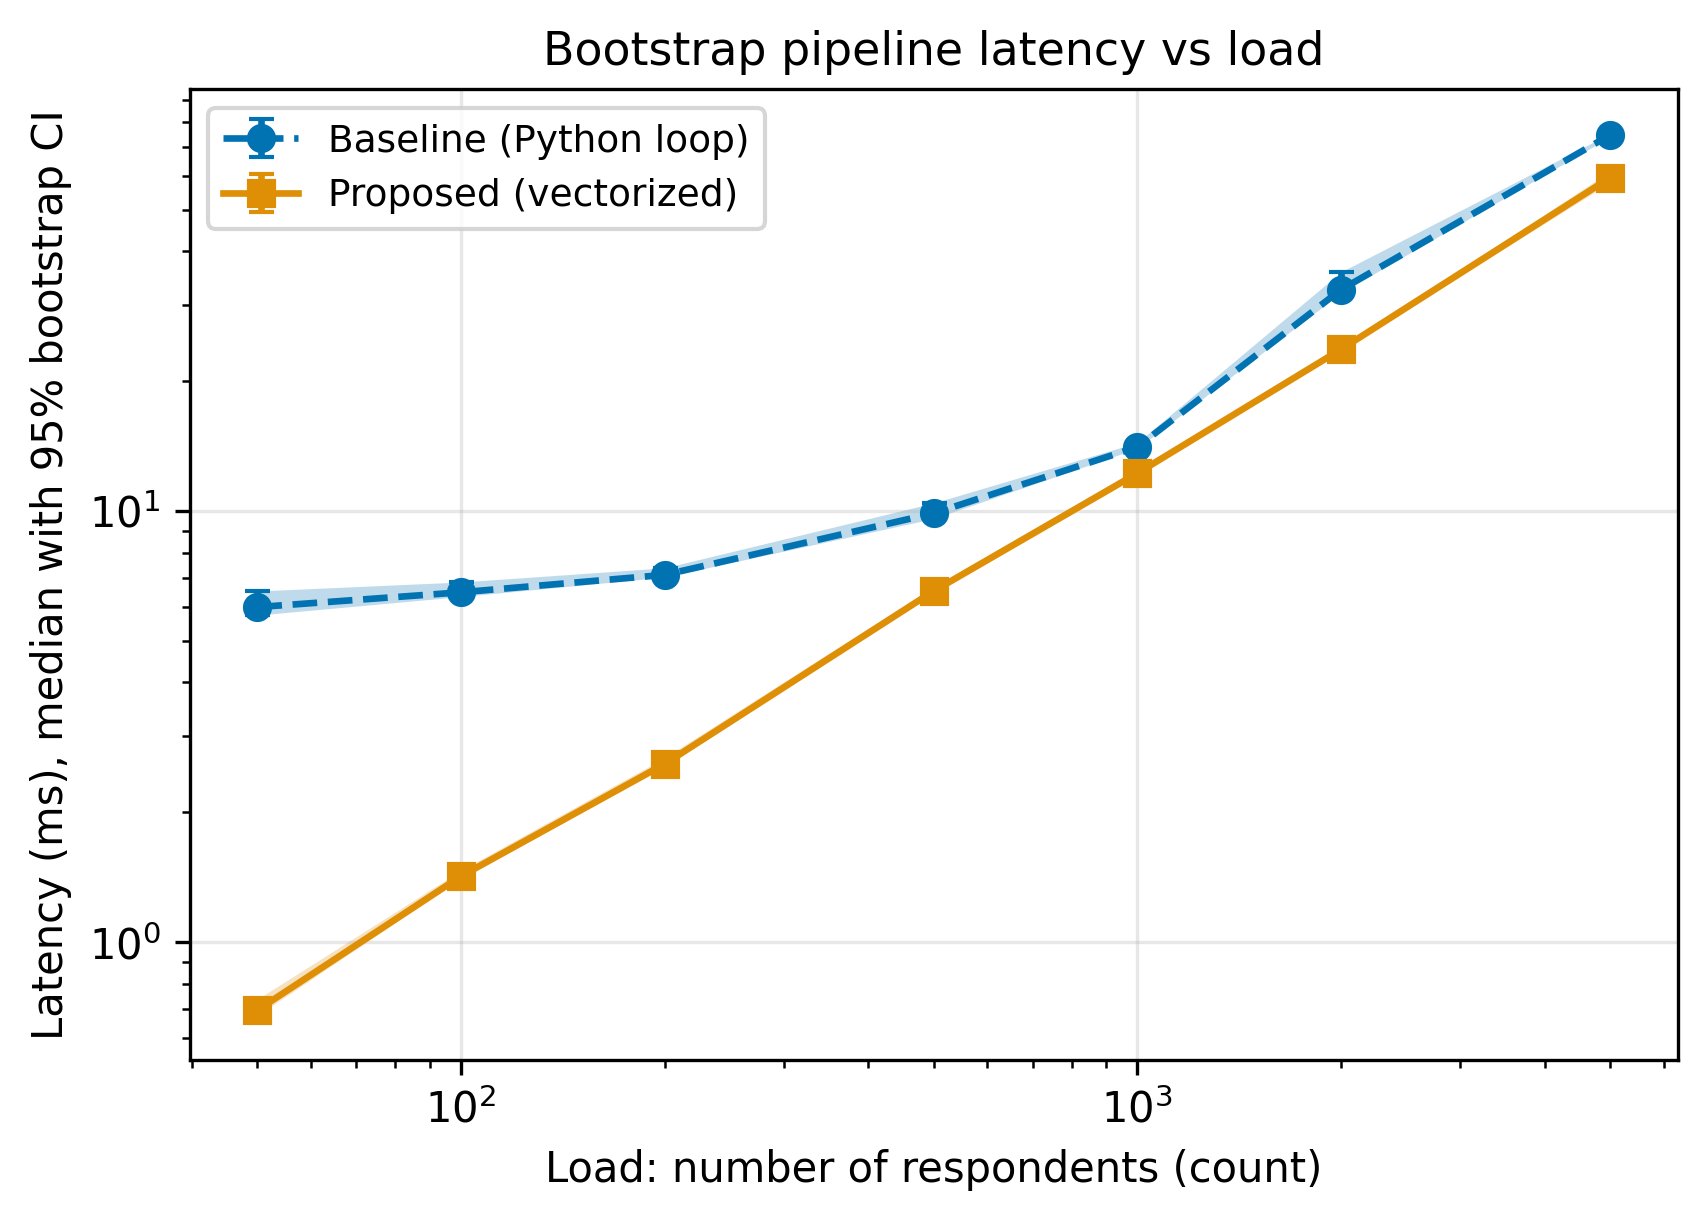

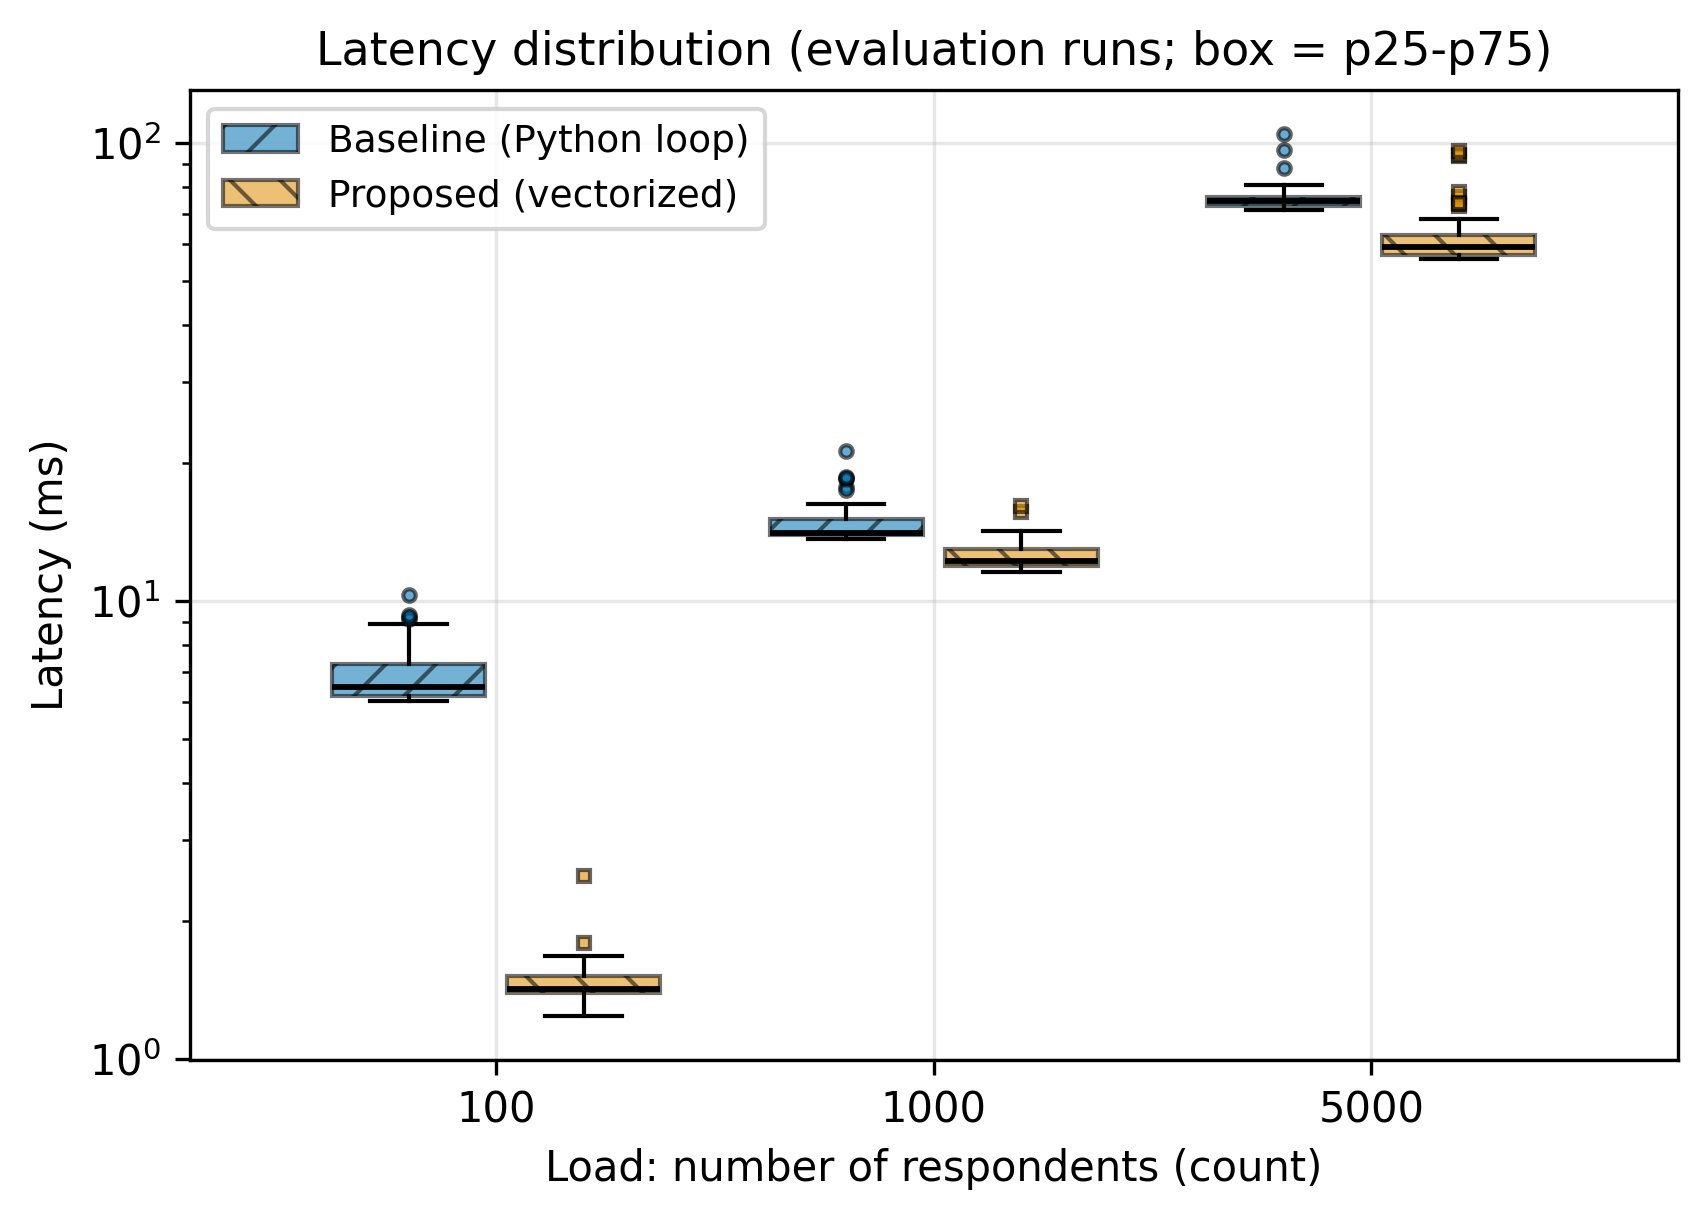

In [10]:
display(Image(filename=str(FIG_DIR / "fig1_latency_vs_load.png"), width=520))
display(Image(filename=str(FIG_DIR / "fig2_distribution_boxplot.png"), width=520))

## 4. Conclusions

The statements below are computed from the data, so they always match the tables above.

In [11]:
sp = readme_table["Speed-up (x)"]
mem_ratio = mem["proposed"] / mem["baseline"]
cold_max = cold["first / median"].max()
print(f"1. The proposed method is {sp.min():.1f}x to {sp.max():.1f}x faster than the baseline "
      f"(median latency) across all loads.")
print(f"2. Maximum error rate over all methods and loads: {summary['error_rate'].max():.1%}.")
if cold_max >= 1.5:
    print(f"3. The very first run is up to {cold_max:.2f}x slower than the evaluation median, "
          f"which confirms that warm-up runs must be discarded.")
else:
    print(f"3. The very first run is at most {cold_max:.2f}x the evaluation median; "
          f"the cold-start effect is small here, but warm-up runs are still discarded as a precaution.")
print(f"4. The proposed method uses {mem_ratio.min():.0f}x to {mem_ratio.max():.0f}x more peak memory "
      f"than the baseline: speed is bought with memory.")

1. The proposed method is 1.1x to 8.6x faster than the baseline (median latency) across all loads.
2. Maximum error rate over all methods and loads: 0.0%.
3. The very first run is up to 12.86x slower than the evaluation median, which confirms that warm-up runs must be discarded.
4. The proposed method uses 11x to 43x more peak memory than the baseline: speed is bought with memory.


**Limitations.** All data are synthetic and were measured on a single machine, so absolute times depend on the hardware. The confidence intervals of the median are narrow because timing noise is small compared with the median. The benchmark describes the performance of the analysis pipeline, not the conclusions of the survey study.